In [54]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [55]:
df = pd.read_csv("../data/ai4i2020.csv")

In [56]:
df.head()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [57]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  str    
 2   Type                     10000 non-null  str    
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3), int64(9), str(2)
me

In [58]:
df.columns

Index(['UDI', 'Product ID', 'Type', 'Air temperature [K]',
       'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]',
       'Tool wear [min]', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF',
       'RNF'],
      dtype='str')

In [59]:
df.shape

(10000, 14)

In [60]:
df.duplicated().sum()

np.int64(0)

In [61]:
df.isnull().sum()

UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64

In [62]:
df.describe()

,UDI,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000
mean,5000.50000,300.004930,310.005560,1538.776100,39.986910,107.951000,0.033900,0.004600,0.011500,0.009500,0.009800,0.00190
std,2886.89568,2.000259,1.483734,179.284096,9.968934,63.654147,0.180981,0.067671,0.106625,0.097009,0.098514,0.04355
min,1.00000,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,2500.75000,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
50%,5000.50000,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
75%,7500.25000,301.500000,311.100000,1612.000000,46.800000,162.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
max,10000.00000,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000


In [63]:
df["Machine failure"].value_counts()

Machine failure
0    9661
1     339
Name: count, dtype: int64

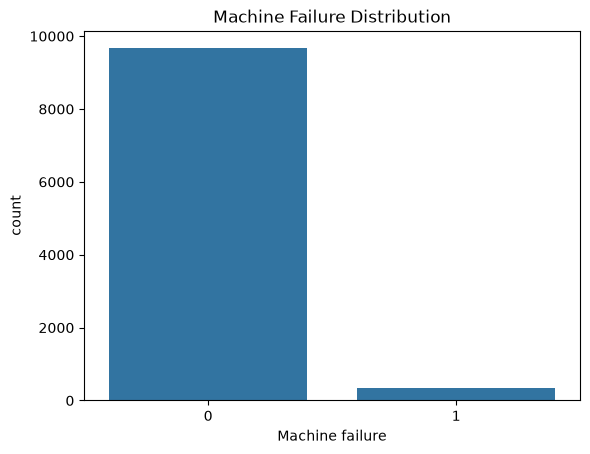

In [64]:
sns.countplot(data=df, x="Machine failure")
plt.title("Machine Failure Distribution")
plt.show()

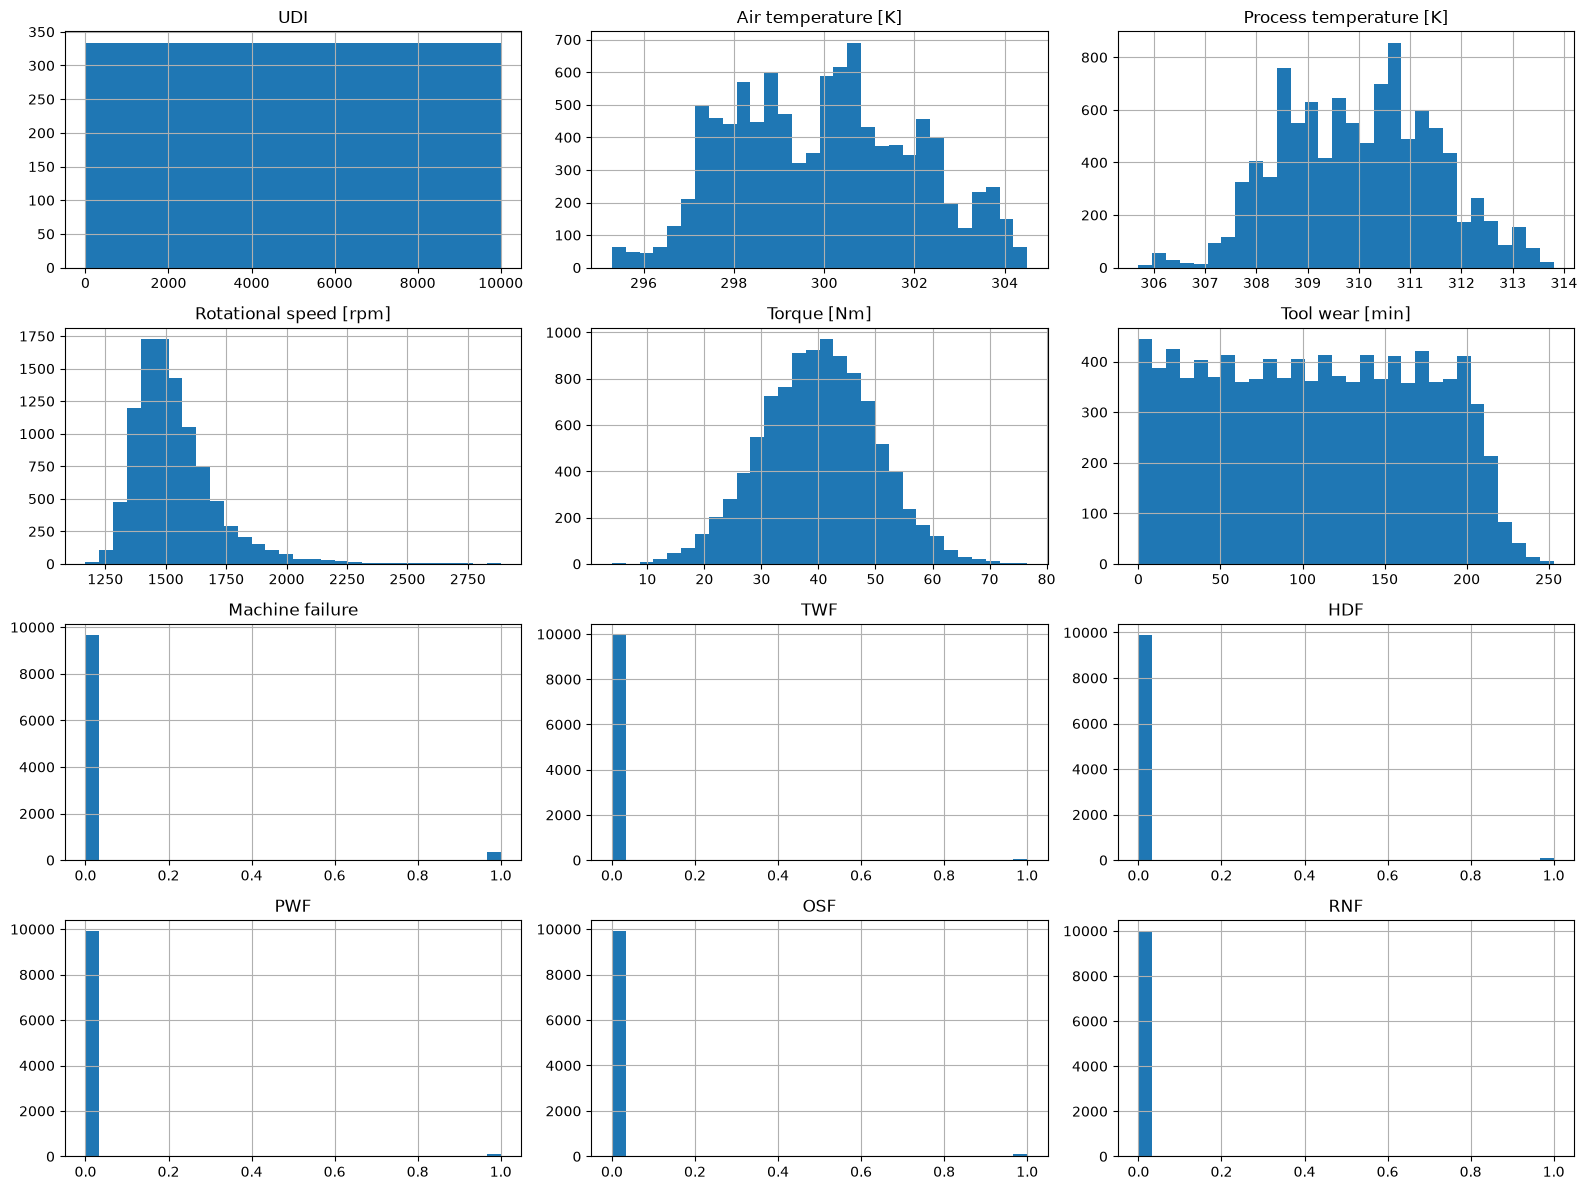

In [65]:
df.hist(figsize=(16, 12), bins=30)
plt.tight_layout()
plt.show()

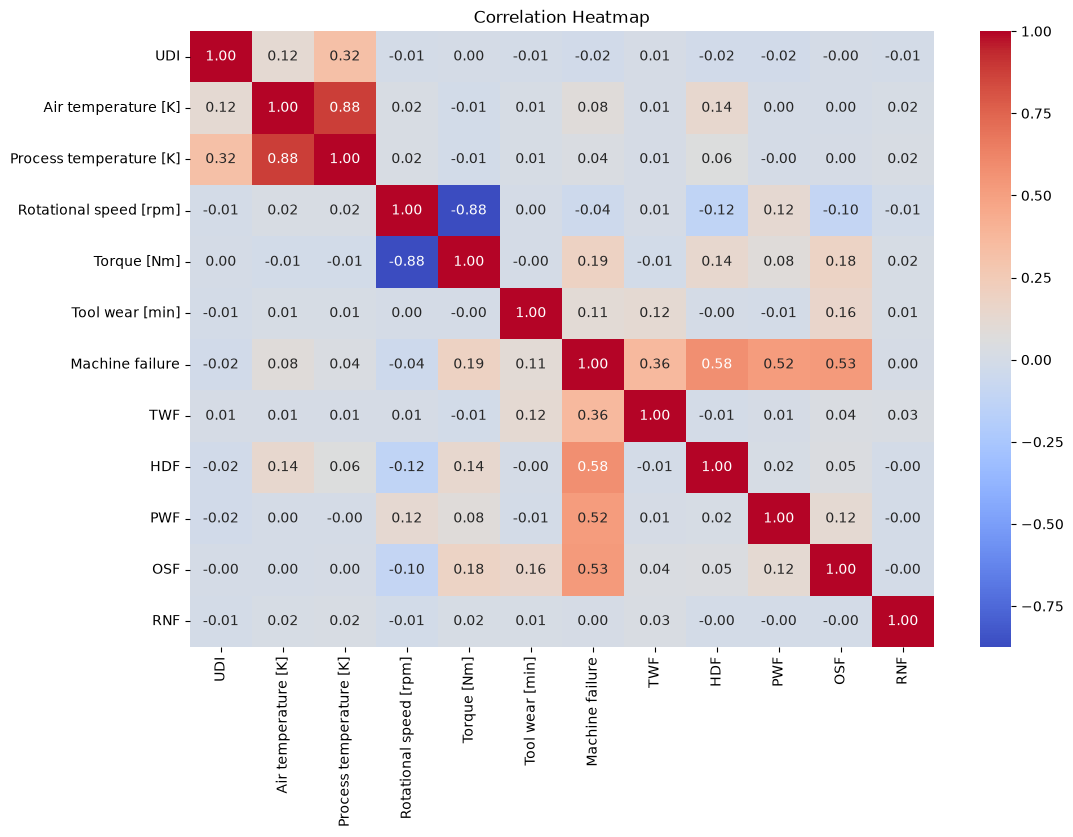

In [66]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    df.select_dtypes(include="number").corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()

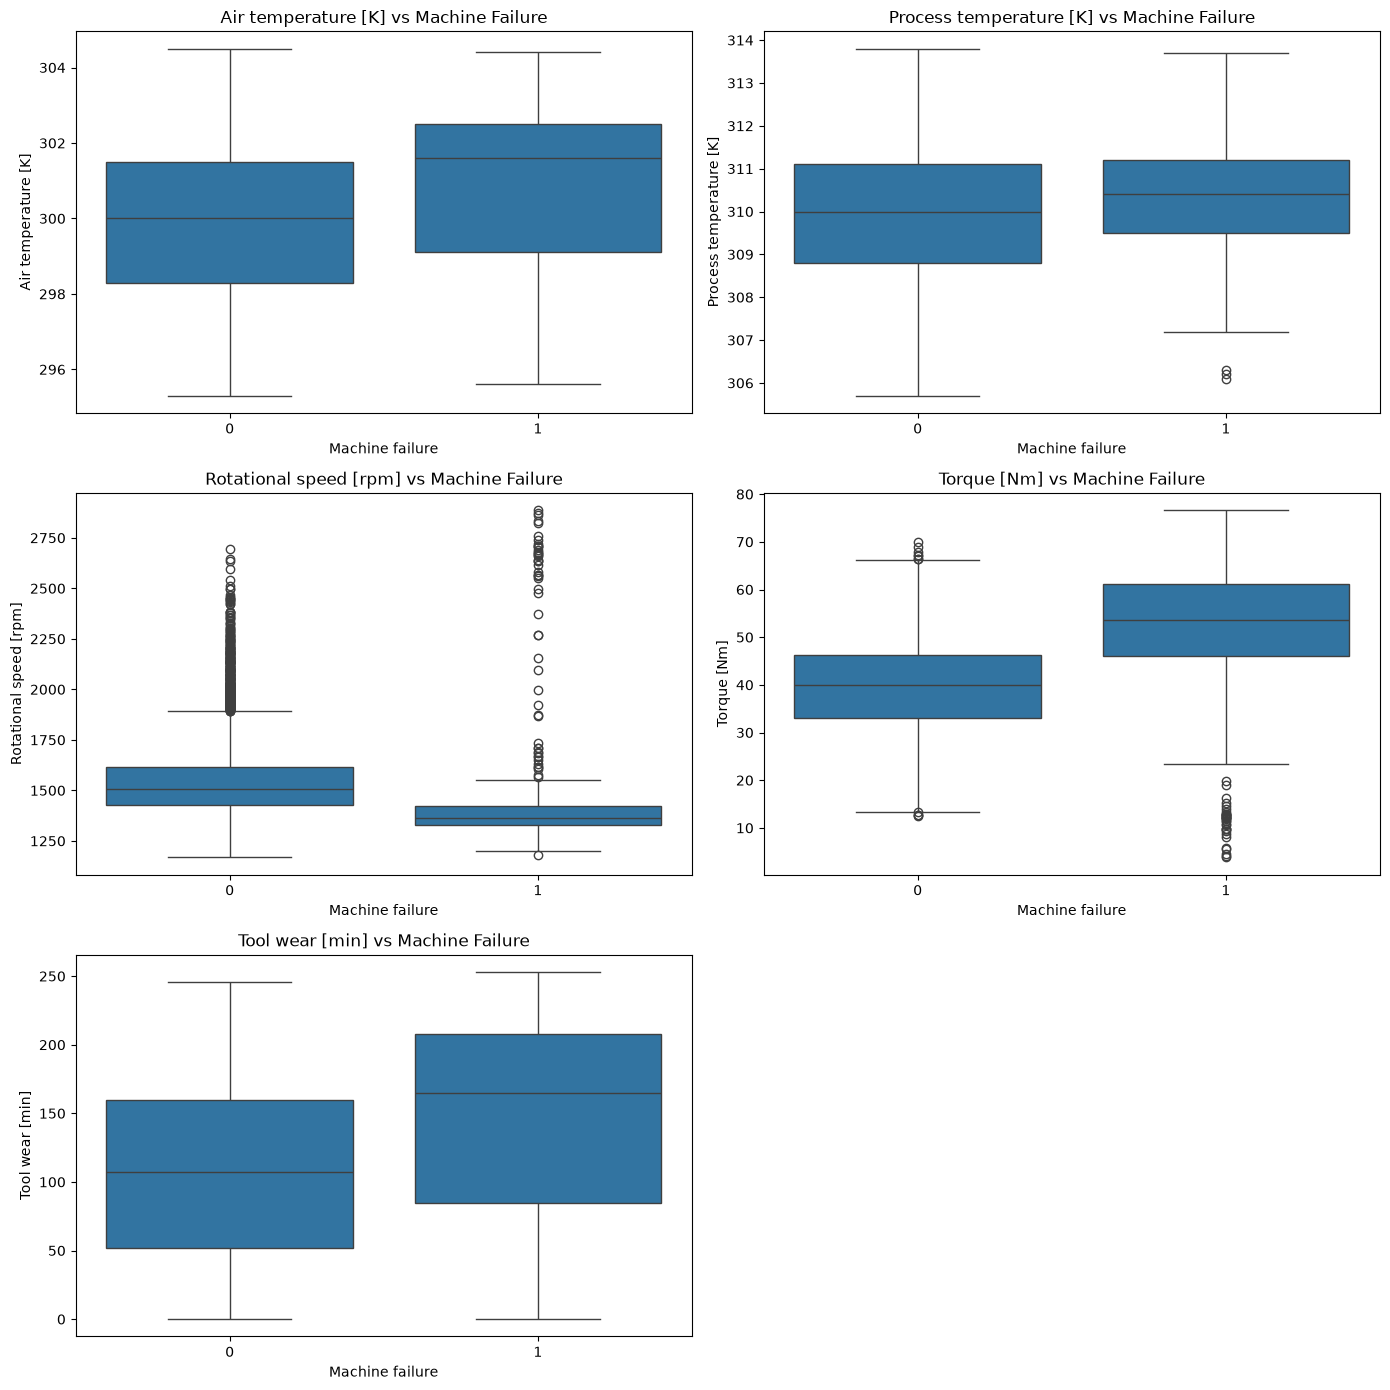

In [67]:
features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

fig, axes = plt.subplots(3, 2, figsize=(14, 14))
axes = axes.flatten()

for i, feature in enumerate(features):
    sns.boxplot(
        data=df,
        x="Machine failure",
        y=feature,
        ax=axes[i]
    )
    axes[i].set_title(f"{feature} vs Machine Failure")

axes[-1].axis("off")
plt.tight_layout()
plt.show()

In [68]:
failure_data = df[df["Machine failure"] == 1]

failure_data = failure_data.drop(
    columns=["UDI", "Product ID", "TWF", "HDF", "PWF", "OSF", "RNF"]
)

display(failure_data.head(20))

,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure
50,L,298.9,309.1,2861,4.6,143,1
69,L,298.9,309.0,1410,65.7,191,1
77,L,298.8,308.9,1455,41.3,208,1
160,L,298.4,308.2,1282,60.7,216,1
161,L,298.3,308.1,1412,52.3,218,1
168,L,298.4,308.3,1433,62.3,20,1
194,M,298.2,308.5,2678,10.7,86,1
207,M,298.4,308.7,1421,60.7,119,1
242,L,298.0,308.2,1348,58.8,202,1
248,L,298.0,308.3,1362,56.8,216,1


## EDA

In [69]:
target = "Machine failure"

drop_cols = [
    "Machine failure",
    "UDI",
    "Product ID",
    "TWF",
    "HDF",
    "PWF",
    "OSF",
    "RNF"
]

X = df.drop(columns=drop_cols, errors="ignore")
y = df[target]

print("Features:", X.columns.tolist())
print("X shape:", X.shape)
print("y shape:", y.shape)

Features: ['Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']
X shape: (10000, 6)
y shape: (10000,)


In [70]:
from sklearn.model_selection import train_test_split

In [71]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

In [72]:
X_train.shape

(8000, 6)

In [73]:
y_train.shape

(8000,)

In [74]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import OrdinalEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier

In [75]:
categorical_features = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()

numerical_features = X.select_dtypes(
    include=np.number
).columns.tolist()

preprocessor = ColumnTransformer(
    transformers=[
        ("categorical", OneHotEncoder(handle_unknown="ignore"),
         categorical_features),
        ("numerical", "passthrough", numerical_features)
    ]
)

model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

model.fit(X_train, y_train)

print("Model training completed!")

C:\Users\anshr\AppData\Local\Temp\ipykernel_27488\3187700169.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X.select_dtypes(


Model training completed!


              precision    recall  f1-score   support

  No Failure       0.99      0.99      0.99      1932
     Failure       0.71      0.66      0.69        68

    accuracy                           0.98      2000
   macro avg       0.85      0.83      0.84      2000
weighted avg       0.98      0.98      0.98      2000

ROC-AUC: 0.9720953598830837


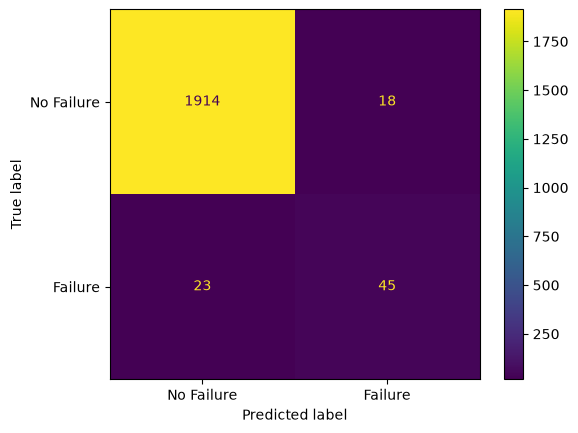

In [76]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score
)

y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

print(classification_report(
    y_test,
    y_pred,
    target_names=["No Failure", "Failure"],
    zero_division=0
))

print("ROC-AUC:", roc_auc_score(y_test, y_prob))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["No Failure", "Failure"]
)

plt.show()

In [77]:
import joblib
from pathlib import Path

artifact_dir = Path("../artifacts")
artifact_dir.mkdir(parents=True, exist_ok=True)

joblib.dump(model, artifact_dir / "mechmind_model.joblib")

print("Model saved successfully!")

Model saved successfully!


In [78]:
from pathlib import Path

model_path = Path("../artifacts/mechmind_model.joblib")

print("Model exists:", model_path.exists())
print("Model path:", model_path.resolve())

Model exists: True
Model path: C:\Users\anshr\Desktop\MechMind Ai\ml\artifacts\mechmind_model.joblib


Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      1932
           1       0.71      0.66      0.69        68

    accuracy                           0.98      2000
   macro avg       0.85      0.83      0.84      2000
weighted avg       0.98      0.98      0.98      2000

Confusion Matrix:
[[1914   18]
 [  23   45]]


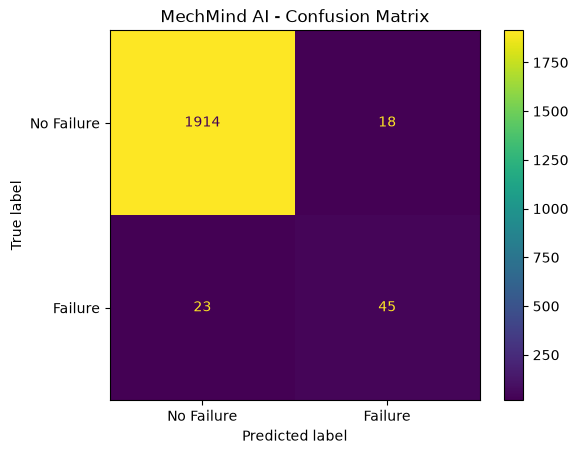

ROC-AUC: 0.9721


In [79]:

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score
)
import matplotlib.pyplot as plt

# Predict on unseen test data
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

# Classification metrics
print("Classification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

# Confusion matrix
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["No Failure", "Failure"]
)
plt.title("MechMind AI - Confusion Matrix")
plt.show()

# ROC-AUC
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 4))


In [80]:

from sklearn.metrics import classification_report, confusion_matrix

# Get predicted failure probabilities
y_prob = model.predict_proba(X_test)[:, 1]

# Experiment with a lower threshold
threshold = 0.30
y_pred_adjusted = (y_prob >= threshold).astype(int)

print("Classification Report (threshold = 0.30):")
print(
    classification_report(
        y_test,
        y_pred_adjusted,
        target_names=["No Failure", "Failure"],
        zero_division=0
    )
)

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_adjusted))


Classification Report (threshold = 0.30):
              precision    recall  f1-score   support

  No Failure       0.99      0.97      0.98      1932
     Failure       0.51      0.84      0.64        68

    accuracy                           0.97      2000
   macro avg       0.75      0.91      0.81      2000
weighted avg       0.98      0.97      0.97      2000

Confusion Matrix:
[[1878   54]
 [  11   57]]
